
[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.
Data folder: c:\Users\rypri\OneDrive\文件\5th sem\probablity reasoning\Bayesian-claim-truthfulness-project\data
Results go to: c:\Users\rypri\OneDrive\文件\5th sem\probablity reasoning\Bayesian-claim-truthfulness-project\outputs

== Dataset summary (binary: True = 'true' or 'mostly-true') ==
         claims    True   False  share_True  speakers
train  10236.0  3638.0  6598.0       0.355    2909.0
valid   1283.0   420.0   863.0       0.327     662.0
test    1267.0   449.0   818.0       0.354     636.0

== Leakage check: speakers whose history has exactly one claim ==
        claims_with_total_history_1  share_where_history_equals_own_label
train                       1648.0                                 0.907
valid                        199.0                                 0.935
test                         178.0                                 0.910

Tb-NB threshold on the log-odds score: tau = -1.300 (0 would be the def

,accuracy,balanced_acc,macro_F1,MCC,AUC,Brier,log_loss
model,,,,,,,
Majority class (always False),0.6456,0.5000,0.3923,0.0000,0.5000,0.2288,0.6501
"NB, leaky history (raw counts)",0.6875,0.6680,0.6646,0.3304,0.7440,0.2239,0.7506
NB baseline (corrected history),0.6401,0.6193,0.6157,0.2336,0.6713,0.2521,0.7949
+ Tb-NB threshold,0.5754,0.6194,0.5750,0.2349,0.6713,0.2521,0.7949
+ iTb-NB second stage,0.6046,0.6064,0.5927,0.2037,0.6713,0.2521,0.7949
"NB, kernel-density numeric likelihoods + threshold",0.5848,0.6247,0.5840,0.2436,0.6761,0.2496,0.7781
"NB, quantile-based numeric likelihoods + threshold (Paper 3)",0.5935,0.6159,0.5892,0.2225,0.6686,0.2519,0.7889
+ ensemble of evidence groups & feature selection (Paper 1),0.6085,0.6215,0.6011,0.2324,0.6697,0.2108,0.6085
FULL: kde likelihoods + ensemble + selection + threshold,0.5991,0.6277,0.5962,0.2462,0.6740,0.2099,0.6063


===== RESULTS: VALIDATION SET =====


,accuracy,balanced_acc,macro_F1,MCC,AUC,Brier,log_loss
model,,,,,,,
Majority class (always False),0.6726,0.5000,0.4021,0.0000,0.5000,0.2210,0.6340
"NB, leaky history (raw counts)",0.7038,0.6729,0.6696,0.3400,0.7424,0.2196,0.7401
NB baseline (corrected history),0.6547,0.6168,0.6146,0.2299,0.6701,0.2493,0.7977
+ Tb-NB threshold,0.5822,0.6161,0.5767,0.2194,0.6701,0.2493,0.7977
+ iTb-NB second stage,0.6313,0.6245,0.6097,0.2356,0.6701,0.2493,0.7977
"NB, kernel-density numeric likelihoods + threshold",0.5838,0.6136,0.5771,0.2142,0.6721,0.2488,0.7948
"NB, quantile-based numeric likelihoods + threshold (Paper 3)",0.6064,0.6164,0.5926,0.2185,0.6731,0.2458,0.7838
+ ensemble of evidence groups & feature selection (Paper 1),0.6165,0.6184,0.5992,0.2228,0.6693,0.2038,0.5930
FULL: kde likelihoods + ensemble + selection + threshold,0.5939,0.6126,0.5836,0.2114,0.6695,0.2040,0.5933


fig1_evidence_by_feature.png


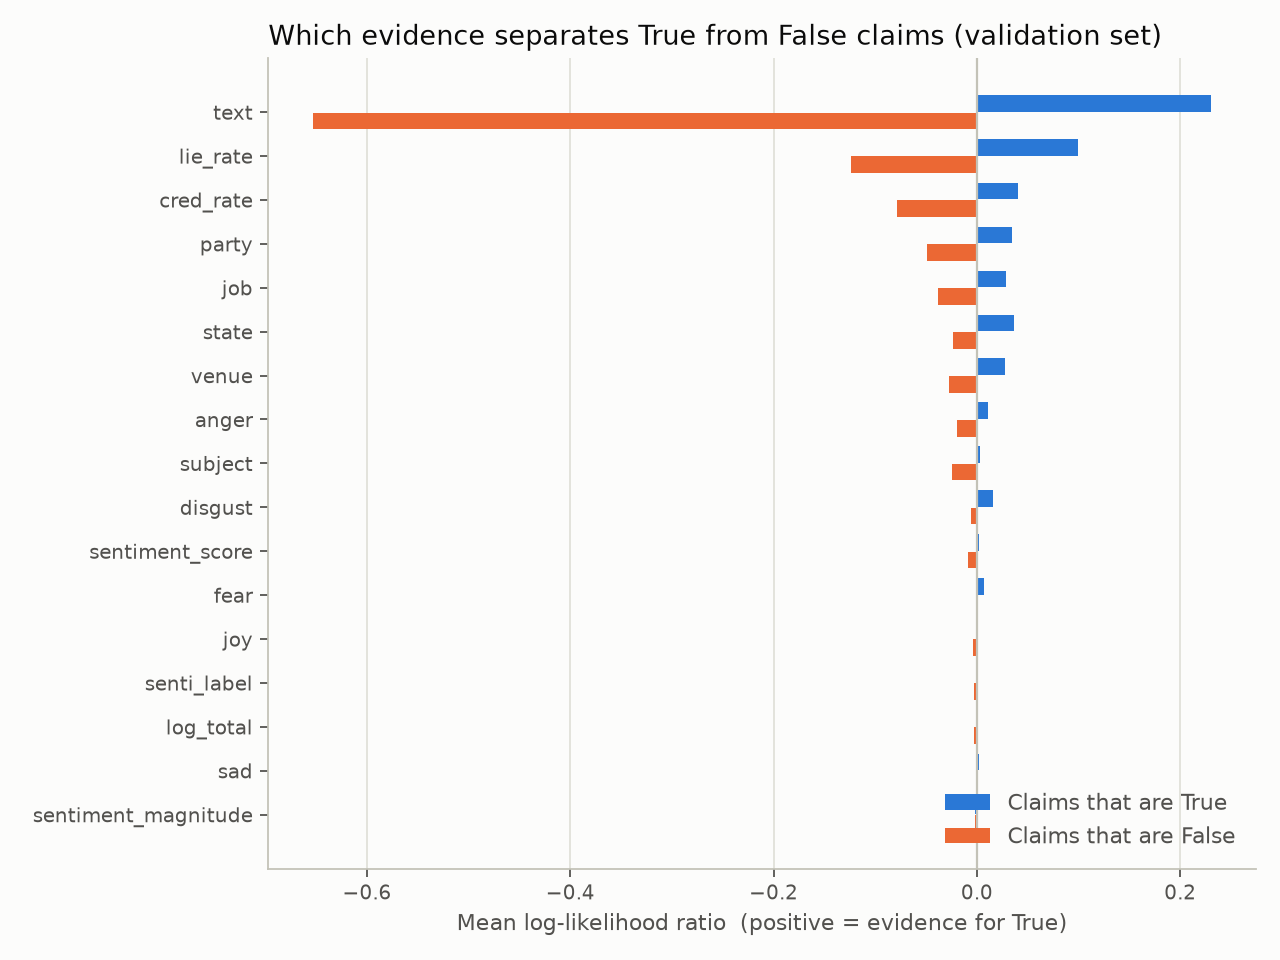

fig2_evidence_waterfall.png


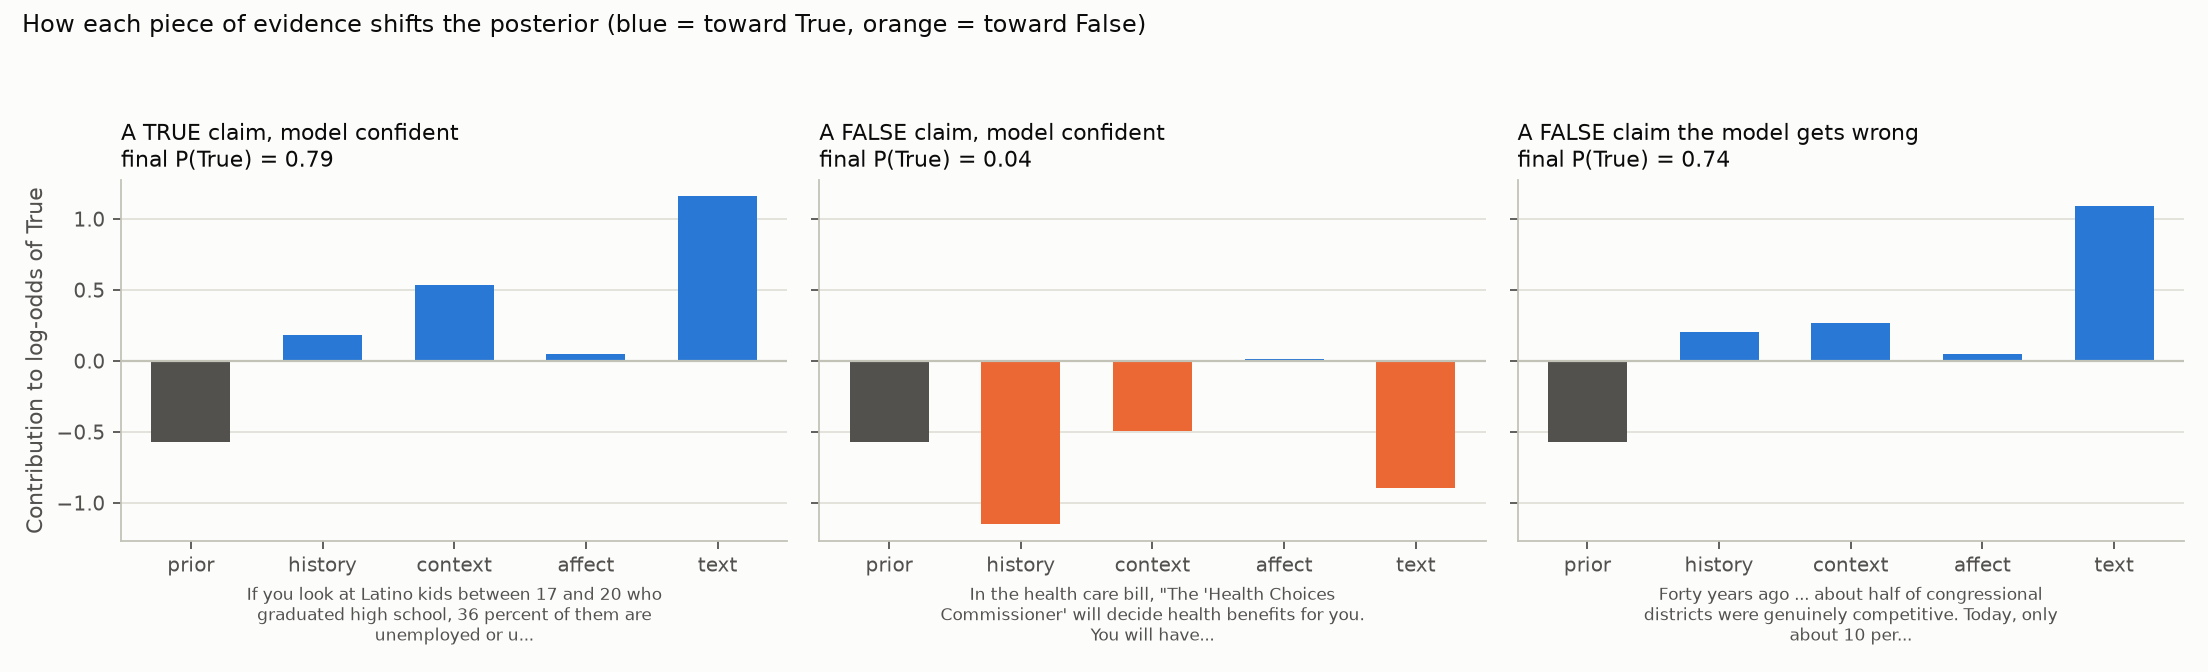

fig3_calibration.png


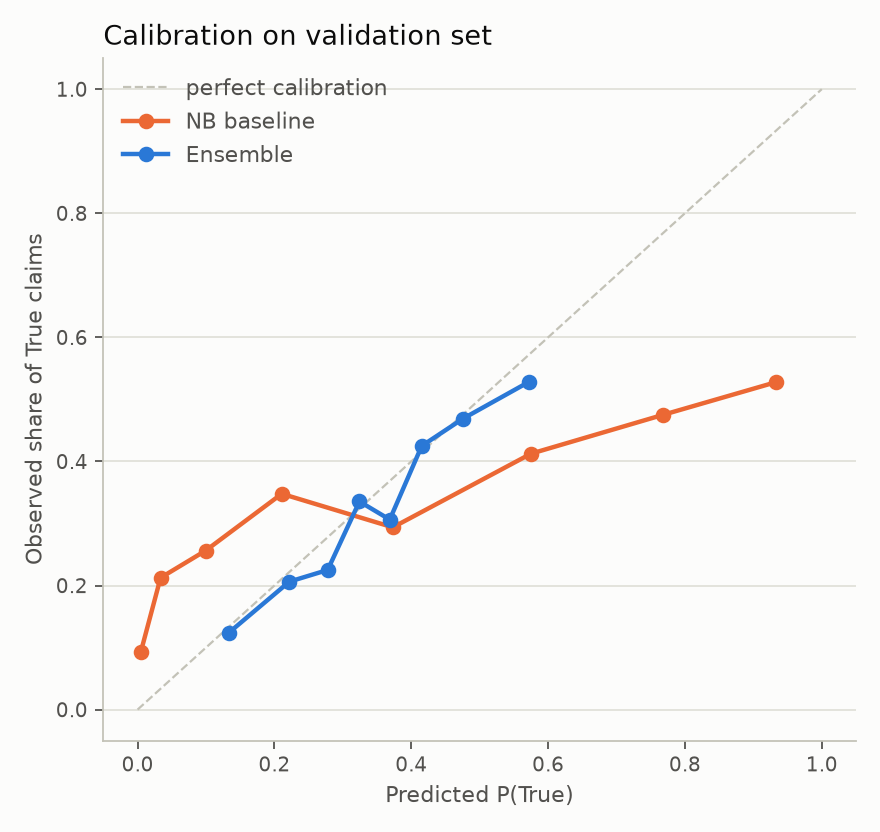

fig4_ablation_mcc.png


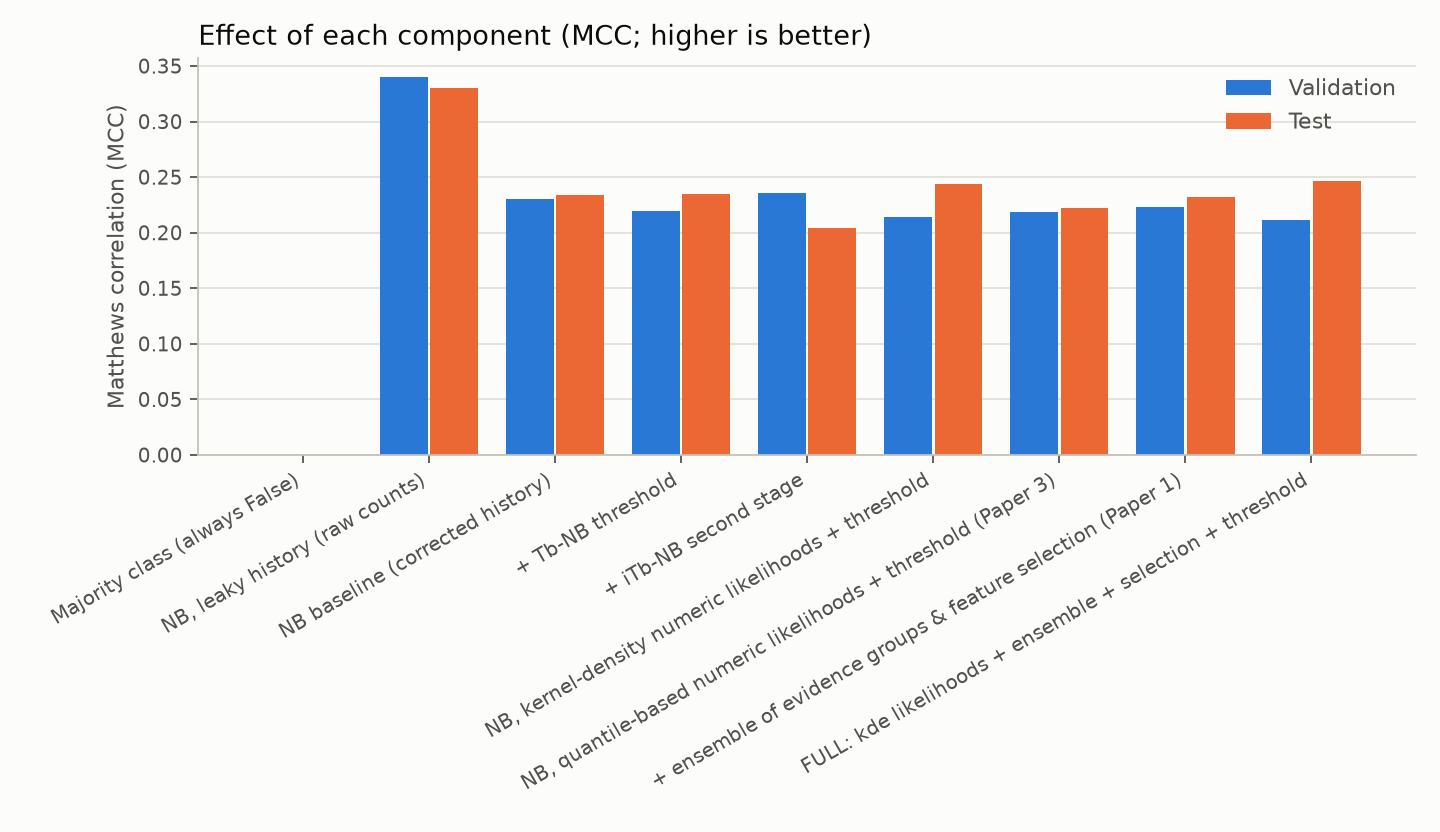

In [1]:
# ======================================================================================
# ONE CELL: Naive Bayesian analysis of claim truthfulness (Sentimental LIAR, no deep learning)
# Put the 'data' folder (train_final.csv, valid_final.csv, test_final.csv) in the project folder,
# next to this notebook or one level above it. Then run this cell. It takes about 30 seconds.
# ======================================================================================
%pip install -q pandas numpy scipy scikit-learn matplotlib

"""
Naive Bayesian analysis of claim truthfulness (Sentimental LIAR) -- no deep learning.

Question: given a claim's topic, the speaker's fact-checking history and contextual
information, how does each piece of evidence change the posterior P(claim is True)?

Everything is a probability model:
    log-odds(True | x) = log prior odds + sum_j  log [ P(x_j | True) / P(x_j | False) ]
Each term of the sum is the "weight of evidence" of one feature.

Ideas adapted (simplified) from the three papers:
  * Paper 2 (Romano et al.)  Tb-NB / iTb-NB : decision threshold on the NB log-likelihood-ratio
                              score chosen by K-fold CV; second-stage rule near the threshold.
  * Paper 1 (Peretz et al.)  NBEM-style      : split features by type into sub-models, threshold-based
                              feature selection, and an ensemble that re-weights the evidence groups
                              (weighted Naive Bayes, weights by maximum likelihood).
  * Paper 3 (Redivo et al.)  quantile-based densities fitted by least squares, used as the
                              class-conditional density inside Naive Bayes.

Usage:
    python truthfulness_nb.py --data data --out outputs
where `data` holds train_final.csv, valid_final.csv, test_final.csv (Sentimental LIAR).

Purely probabilistic: Bayes' rule, class-conditional likelihoods, additive smoothing, maximum-likelihood
estimation (the evidence-group weights are fitted by maximising a Bernoulli likelihood, written out below,
no machine-learning classifier is used). scikit-learn is used only for tokenising text, splitting rows into
folds and computing evaluation metrics.

All tuning (smoothing, thresholds, ensemble weights, feature selection, choice of density)
is done on out-of-fold predictions of the TRAIN set only. Validation and test are untouched
hold-outs that are only scored.
"""
import argparse
import os
import re
import textwrap
import warnings

import numpy as np
import pandas as pd
from scipy.optimize import nnls
from scipy.special import expit
from scipy.stats import gaussian_kde
from sklearn.calibration import calibration_curve
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, brier_score_loss, f1_score,
                             log_loss, matthews_corrcoef, roc_auc_score)
from sklearn.model_selection import StratifiedKFold      # only used to split rows into folds

import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

SEED = 42
K = 5          # folds for out-of-fold estimates
CLIP = 3.0     # cap on |log-likelihood-ratio| of a single numeric feature

COUNT_COLS = ["barely_true_counts", "false_counts", "half_true_counts",
              "mostly_true_counts", "pants_on_fire_counts"]
LAB2COL = {"barely-true": "barely_true_counts", "false": "false_counts",
           "half-true": "half_true_counts", "mostly-true": "mostly_true_counts",
           "pants-fire": "pants_on_fire_counts", "true": None}   # 'true' has no count column

CTX = ["party", "job", "state", "subject", "venue"]            # categorical context
AFFECT = ["sentiment_score", "sentiment_magnitude", "anger", "fear", "joy", "disgust", "sad"]
HIST = ["cred_rate", "lie_rate", "log_total"]                  # speaker-history features
CAT_ALL = CTX + ["senti_label"]
GROUP_OF = {**{c: "context" for c in CTX}, "senti_label": "affect",
            **{c: "affect" for c in AFFECT}, **{c: "history" for c in HIST}, "text": "text"}
GROUPS = ["history", "context", "affect", "text"]



# ----------------------------------------------------------------------------- data
def load(data_dir):
    out = {}
    for s in ["train", "valid", "test"]:
        df = pd.read_csv(os.path.join(data_dir, f"{s}_final.csv")).reset_index(drop=True)
        df["y"] = df["label"].isin(["true", "mostly-true"]).astype(int)   # 1 = True
        out[s] = df
    return out


def history_counts(df, corrected):
    """Speaker-history counts. In this dataset the counts INCLUDE the current claim, which leaks
    the label. corrected=True subtracts the claim's own label to recover the history before it."""
    H = df[COUNT_COLS].astype(float).copy()
    if corrected:
        for lab, col in LAB2COL.items():
            if col:
                H.loc[df["label"] == lab, col] -= 1
        H = H.clip(lower=0)
    return H


def venue_bucket(s):
    if not isinstance(s, str):
        return "unknown"
    s = s.lower()
    rules = [("debate", r"debate"),
             ("social", r"facebook|twitter|tweet|social|instagram|youtube|blog|post"),
             ("media", r"tv|television|interview|cnn|fox|msnbc|show|radio|npr|abc|cbs|nbc|meet the press"),
             ("speech", r"speech|remarks|address|rally|convention|floor|forum|town hall"),
             ("ad_mail", r"mailer|\bads?\b|flier|brochure|campaign|commercial|website|web site|mail"),
             ("press", r"press|news release|news conference|statement"),
             ("hearing", r"hearing|testimony|committee"),
             ("written", r"email|letter|op-ed|column|article|report|book")]
    for name, pat in rules:
        if re.search(pat, s):
            return name
    return "other"


class Prep:
    """Turns raw rows into model features. Category vocabularies come from TRAIN only."""

    def __init__(self, train, top_job=30, top_state=25, top_subj=25):
        self.vocab = {
            "job": self._top(self._job(train), top_job),
            "state": self._top(self._state(train), top_state),
            "subject": self._top(self._subject(train), top_subj)}

    @staticmethod
    def _top(s, n):
        return set(s.value_counts().head(n).index)

    @staticmethod
    def _job(df): return df["speaker_job"].fillna("unknown").str.lower().str.strip()

    @staticmethod
    def _state(df): return df["state_info"].fillna("unknown").str.lower().str.strip()

    @staticmethod
    def _subject(df): return df["subject"].fillna("unknown").str.split(",").str[0].str.strip().str.lower()

    def transform(self, df, corrected=True):
        F = pd.DataFrame(index=df.index)
        F["party"] = df["party_affiliation"].fillna("none").str.lower()
        for name, ser in [("job", self._job(df)), ("state", self._state(df)), ("subject", self._subject(df))]:
            F[name] = ser.where(ser.isin(self.vocab[name]), "other")
        F["venue"] = df["context"].map(venue_bucket)
        F["senti_label"] = df["sentiment"].fillna("NEUTRAL")
        for c in AFFECT:
            F[c] = df[c].astype(float)
        H = history_counts(df, corrected)
        tot = H.sum(axis=1)
        F["cred_rate"] = (H["mostly_true_counts"] + 1) / (tot + 3)                     # shrunk share of 'mostly true'
        F["lie_rate"] = (H["false_counts"] + H["pants_on_fire_counts"] + 1) / (tot + 3)  # shrunk share of false/pants-fire
        F["log_total"] = np.log1p(tot)                                                  # how much history exists
        F["statement"] = df["statement"].fillna("").astype(str)
        return F


# ----------------------------------------------------------------------------- likelihood blocks
class CatLL:
    """Categorical likelihoods with Lidstone (additive) smoothing."""

    def __init__(self, alpha=1.0):
        self.alpha = alpha

    def fit(self, X, y):
        self.cols, self.t = list(X.columns), {}
        for c in self.cols:
            cats = X[c].unique()
            kc = len(cats) + 1                       # +1 for unseen categories
            lp = {}
            for k in (0, 1):
                cnt = X[c][y == k].value_counts()
                tot = cnt.sum() + self.alpha * kc
                lp[k] = {v: np.log((cnt.get(v, 0) + self.alpha) / tot) for v in cats}
                lp[k]["__u"] = np.log(self.alpha / tot)
            self.t[c] = lp
        return self

    def llr(self, X):
        out = np.zeros((len(X), len(self.cols)))
        for j, c in enumerate(self.cols):
            l1, l0 = self.t[c][1], self.t[c][0]
            out[:, j] = [l1.get(v, l1["__u"]) - l0.get(v, l0["__u"]) for v in X[c]]
        return out


class GaussLL:
    """Class-conditional Gaussian density per numeric feature."""

    def fit(self, X, y):
        X = np.asarray(X, float)
        v = X.var(0) + 1e-9
        self.mu = [X[y == k].mean(0) for k in (0, 1)]
        self.var = [np.maximum(X[y == k].var(0), 1e-3 * v) for k in (0, 1)]
        return self

    def llr(self, X):
        X = np.asarray(X, float)
        ll = [-0.5 * np.log(2 * np.pi * self.var[k]) - 0.5 * (X - self.mu[k]) ** 2 / self.var[k] for k in (0, 1)]
        return np.clip(ll[1] - ll[0], -CLIP, CLIP)


class KdeLL:
    """Class-conditional kernel density estimate per numeric feature (non-parametric comparison)."""

    def fit(self, X, y):
        X = np.asarray(X, float)
        rng = np.random.RandomState(SEED)
        self.k = []
        for j in range(X.shape[1]):
            row = []
            for c in (0, 1):
                x = X[y == c, j]
                if len(x) > 3000:
                    x = rng.choice(x, 3000, replace=False)
                x = x + rng.normal(0, 1e-6 + 1e-3 * X[:, j].std(), len(x))   # avoid singular KDE on ties
                row.append(gaussian_kde(x))
            self.k.append(row)
        return self

    def llr(self, X):
        X = np.asarray(X, float)
        out = np.zeros(X.shape)
        for j in range(X.shape[1]):
            out[:, j] = np.log(self.k[j][1](X[:, j]) + 1e-6) - np.log(self.k[j][0](X[:, j]) + 1e-6)
        return np.clip(out, -CLIP, CLIP)


class QuantLL:
    """Quantile-based density (inspired by Redivo et al., 2023).

    The quantile function is a non-negative combination of basic quantile functions
        Q(u) = th0 + th1*u + th2*(-log(1-u)) + th3*log(u)       th1,th2,th3 >= 0
    (uniform + right exponential tail + left exponential tail), which is again a valid quantile
    function. It is fitted by least squares between sorted data and Q at the plotting positions
    (non-negative least squares). The density follows from f(x) = 1 / Q'(u) at u = Q^-1(x).
    """

    def fit(self, X, y):
        X = np.asarray(X, float)
        self.m, self.s = X.mean(0), X.std(0) + 1e-9          # pooled standardisation (cancels in the ratio)
        ug = np.linspace(1e-4, 1 - 1e-4, 3000)
        self.models = []
        for j in range(X.shape[1]):
            row = []
            for c in (0, 1):
                z = np.sort((X[y == c, j] - self.m[j]) / self.s[j])
                n = len(z)
                u = (np.arange(1, n + 1) - 0.5) / n
                B = np.column_stack([np.ones(n), -np.ones(n), u, -np.log1p(-u), np.log(u)])
                th, _ = nnls(B, z)
                t0, t1, t2, t3 = th[0] - th[1], th[2], th[3], th[4]
                Q = t0 + t1 * ug - t2 * np.log1p(-ug) + t3 * np.log(ug) + 1e-9 * ug
                dQ = np.maximum(t1 + t2 / (1 - ug) + t3 / ug, 1e-6)
                row.append((Q, dQ))
            self.models.append(row)
        return self

    def _dens(self, j, c, z):
        Q, dQ = self.models[j][c]
        return 1.0 / np.maximum(np.interp(z, Q, dQ), 1e-6)

    def llr(self, X):
        X = np.asarray(X, float)
        out = np.zeros(X.shape)
        for j in range(X.shape[1]):
            z = (X[:, j] - self.m[j]) / self.s[j]
            out[:, j] = np.log(self._dens(j, 1, z) + 1e-4) - np.log(self._dens(j, 0, z) + 1e-4)
        return np.clip(out, -CLIP, CLIP)


class TextLL:
    """Multinomial-style Naive Bayes over binary bag-of-words, returned as one evidence column."""

    def __init__(self, alpha=1.0, min_df=5, max_features=6000):
        self.alpha, self.min_df, self.max_features = alpha, min_df, max_features

    def fit(self, texts, y):
        self.cv = CountVectorizer(stop_words="english", min_df=self.min_df,
                                  max_features=self.max_features, binary=True)
        X = self.cv.fit_transform(texts)
        lt = []
        for k in (0, 1):
            c = np.asarray(X[y == k].sum(0)).ravel() + self.alpha
            lt.append(np.log(c / c.sum()))
        self.w = lt[1] - lt[0]
        return self

    def llr(self, texts):
        return np.asarray(self.cv.transform(texts) @ self.w).reshape(-1, 1)


DENS = {"gauss": GaussLL, "kde": KdeLL, "quantile": QuantLL}


class BlockNB:
    """Naive Bayes whose features are blocks: categorical + numeric + text. llr() returns the
    per-feature log-likelihood ratios, so the log-odds is prior + llr.sum(axis=1)."""

    def __init__(self, density="gauss", alpha=1.0, use_text=True):
        self.density, self.alpha, self.use_text = density, alpha, use_text
        self.names = CAT_ALL + AFFECT + HIST + (["text"] if use_text else [])

    def fit(self, F, y):
        y = np.asarray(y)
        self.cat = CatLL(self.alpha).fit(F[CAT_ALL], y)
        self.num = DENS[self.density]().fit(F[AFFECT + HIST].values, y)
        if self.use_text:
            self.txt = TextLL().fit(F["statement"].values, y)
        self.prior = float(np.log(y.mean() / (1 - y.mean())))
        return self

    def llr(self, F):
        parts = [self.cat.llr(F[CAT_ALL]), self.num.llr(F[AFFECT + HIST].values)]
        if self.use_text:
            parts.append(self.txt.llr(F["statement"].values))
        return pd.DataFrame(np.hstack(parts), columns=self.names, index=F.index)


def oof_llr(Ftr, ytr, evals, **spec):
    """Out-of-fold LLRs for train (5-fold), plus LLRs for each eval set from a model fit on all train."""
    skf = StratifiedKFold(K, shuffle=True, random_state=SEED)
    L = None
    for a, b in skf.split(Ftr, ytr):
        m = BlockNB(**spec).fit(Ftr.iloc[a], ytr[a])
        l = m.llr(Ftr.iloc[b])
        if L is None:
            L = np.zeros((len(Ftr), l.shape[1]))
            cols = list(l.columns)
        L[b] = l.values
    m = BlockNB(**spec).fit(Ftr, ytr)
    out = {"train": pd.DataFrame(L, columns=cols), "prior": m.prior}
    for k, F in evals.items():
        out[k] = m.llr(F).reset_index(drop=True)
    return out


# ----------------------------------------------------------------------------- decisions & metrics
def best_threshold(y, S, crit="mcc"):
    """Tb-NB step: data-driven threshold on the score, chosen to maximise a criterion."""
    cands = np.quantile(S, np.linspace(0.02, 0.98, 200))
    f = (lambda p: matthews_corrcoef(y, p)) if crit == "mcc" else (lambda p: f1_score(y, p, average="macro"))
    return float(cands[int(np.argmax([f((S > t).astype(int)) for t in cands]))])


def fit_itb(Ftr, ytr, S_oof, tau, spec, band_frac=0.4):
    """iTb-NB (simplified): re-fit a second NB on training claims whose score lies near the
    threshold (the class-overlap region), with its own threshold; used only for claims in that band."""
    dist = np.abs(S_oof - tau)
    h = float(np.quantile(dist, band_frac))
    idx = np.where(dist <= h)[0]
    Fb, yb = Ftr.iloc[idx], ytr[idx]
    S2 = np.zeros(len(idx))
    for a, b in StratifiedKFold(K, shuffle=True, random_state=SEED).split(Fb, yb):
        m = BlockNB(**spec).fit(Fb.iloc[a], yb[a])
        S2[b] = m.prior + m.llr(Fb.iloc[b]).sum(axis=1).values
    return {"tau": tau, "h": h, "tau2": best_threshold(yb, S2), "m2": BlockNB(**spec).fit(Fb, yb)}


def apply_itb(model, F, S1):
    pred = (S1 > model["tau"]).astype(int)
    band = np.abs(S1 - model["tau"]) <= model["h"]
    if band.any():
        m2 = model["m2"]
        S2 = m2.prior + m2.llr(F[band]).sum(axis=1).values
        pred[band] = (S2 > model["tau2"]).astype(int)
    return pred


def metrics(y, S, pred):
    p = np.clip(expit(S), 1e-6, 1 - 1e-6)
    return {"accuracy": accuracy_score(y, pred), "balanced_acc": balanced_accuracy_score(y, pred),
            "macro_F1": f1_score(y, pred, average="macro"), "MCC": matthews_corrcoef(y, pred),
            "AUC": roc_auc_score(y, S), "Brier": brier_score_loss(y, p), "log_loss": log_loss(y, p)}


def group_sums(L, keep=None):
    cols = lambda g: [c for c in L.columns if GROUP_OF[c] == g and (keep is None or c in keep)]
    return pd.DataFrame({g: (L[cols(g)].sum(axis=1) if cols(g) else 0.0) for g in GROUPS})


def fit_weighted_nb(G, y, iters=100):
    """Weighted Naive Bayes fitted by MAXIMUM LIKELIHOOD (Newton-Raphson, written out by hand).

    Model:  log-odds(True) = b + sum_g w_g * L_g      (L_g = summed evidence of evidence group g)
    P(y=1) = 1 / (1 + exp(-log-odds)), and (b, w) maximise the Bernoulli log-likelihood
        sum_i [ y_i log p_i + (1 - y_i) log(1 - p_i) ].
    w_g = 1 for every group (and b = prior log-odds) is plain Naive Bayes; w_g < 1 shrinks a group whose
    features are not independent, which plain Naive Bayes over-counts."""
    X = np.column_stack([np.ones(len(G)), np.asarray(G, float)])
    beta = np.zeros(X.shape[1])
    for _ in range(iters):
        p = expit(X @ beta)
        grad = X.T @ (y - p)                                         # gradient of the log-likelihood
        hess = (X * (p * (1 - p))[:, None]).T @ X + 1e-8 * np.eye(X.shape[1])
        step = np.linalg.solve(hess, grad)
        beta = beta + step
        if np.abs(step).max() < 1e-9:
            break
    return beta                                                       # [b, w_group_1, w_group_2, ...]


def score_weighted_nb(beta, G):
    return beta[0] + np.asarray(G, float) @ beta[1:]


def oof_weighted_nb(G, y):
    """Out-of-fold log-odds from the maximum-likelihood weighted Naive Bayes."""
    S = np.zeros(len(y))
    for a, b in StratifiedKFold(K, shuffle=True, random_state=SEED).split(G, y):
        S[b] = score_weighted_nb(fit_weighted_nb(G.iloc[a], y[a]), G.iloc[b])
    return S


# ----------------------------------------------------------------------------- figures
INK, INK2, GRID, SURF = "#0b0b0b", "#52514e", "#e1e0d9", "#fcfcfb"
BLUE, ORANGE = "#2a78d6", "#eb6834"      # categorical slots 1 and 2 (validated pair)


def style(ax):
    ax.set_facecolor(SURF)
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
    for s in ["left", "bottom"]:
        ax.spines[s].set_color("#c3c2b7")
    ax.tick_params(colors=INK2, labelsize=9)
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)


def fig_evidence(L, y, path):
    d = pd.DataFrame({"True": L[y == 1].mean(), "False": L[y == 0].mean()})
    d["gap"] = (d["True"] - d["False"]).abs()
    d = d.sort_values("gap")
    fig, ax = plt.subplots(figsize=(8, 6), facecolor=SURF)
    pos = np.arange(len(d))
    ax.barh(pos + 0.2, d["True"], height=0.38, color=BLUE, label="Claims that are True")
    ax.barh(pos - 0.2, d["False"], height=0.38, color=ORANGE, label="Claims that are False")
    ax.set_yticks(pos)
    ax.set_yticklabels(d.index, color=INK)
    ax.axvline(0, color="#c3c2b7", linewidth=1)
    ax.set_xlabel("Mean log-likelihood ratio  (positive = evidence for True)", color=INK2)
    ax.set_title("Which evidence separates True from False claims (validation set)", color=INK, loc="left", fontsize=12)
    ax.grid(axis="x", color=GRID, linewidth=0.8)
    ax.grid(axis="y", visible=False)
    style(ax)
    ax.grid(axis="y", visible=False)
    ax.legend(frameon=False, labelcolor=INK2, loc="lower right")
    fig.tight_layout()
    fig.savefig(path, dpi=160, facecolor=SURF)
    plt.close(fig)


def fig_waterfall(examples, path):
    fig, axes = plt.subplots(1, len(examples), figsize=(4.6 * len(examples), 4.2), facecolor=SURF, sharey=True)
    for ax, ex in zip(np.atleast_1d(axes), examples):
        labels = ["prior"] + GROUPS
        vals = [ex["prior"]] + [ex[g] for g in GROUPS]
        colors = [INK2] + [BLUE if v >= 0 else ORANGE for v in vals[1:]]
        ax.bar(labels, vals, color=colors, width=0.6)
        ax.axhline(0, color="#c3c2b7", linewidth=1)
        style(ax)
        ax.set_title(f"{ex['title']}\nfinal P(True) = {ex['post']:.2f}", color=INK, fontsize=10, loc="left")
        ax.set_xlabel(ex["claim"], color=INK2, fontsize=7.5, wrap=True)
    np.atleast_1d(axes)[0].set_ylabel("Contribution to log-odds of True", color=INK2)
    fig.suptitle("How each piece of evidence shifts the posterior (blue = toward True, orange = toward False)",
                 color=INK, fontsize=11, x=0.01, ha="left")
    fig.tight_layout(rect=[0, 0, 1, 0.93])
    fig.savefig(path, dpi=160, facecolor=SURF)
    plt.close(fig)


def fig_calibration(items, y, path):
    fig, ax = plt.subplots(figsize=(5.5, 5.2), facecolor=SURF)
    ax.plot([0, 1], [0, 1], color="#c3c2b7", linewidth=1, linestyle="--", label="perfect calibration")
    for (name, S), col in zip(items, [ORANGE, BLUE]):
        fr, mp = calibration_curve(y, expit(S), n_bins=8, strategy="quantile")
        ax.plot(mp, fr, marker="o", color=col, linewidth=2, label=name)
    ax.set_xlabel("Predicted P(True)", color=INK2)
    ax.set_ylabel("Observed share of True claims", color=INK2)
    ax.set_title("Calibration on validation set", color=INK, loc="left")
    style(ax)
    ax.legend(frameon=False, labelcolor=INK2)
    fig.tight_layout()
    fig.savefig(path, dpi=160, facecolor=SURF)
    plt.close(fig)


def fig_ablation(res_v, res_t, path):
    names = list(res_v.index)
    pos = np.arange(len(names))
    fig, ax = plt.subplots(figsize=(9, 5.2), facecolor=SURF)
    ax.bar(pos - 0.2, res_v["MCC"], width=0.38, color=BLUE, label="Validation")
    ax.bar(pos + 0.2, res_t["MCC"], width=0.38, color=ORANGE, label="Test")
    ax.set_xticks(pos)
    ax.set_xticklabels(names, rotation=30, ha="right", color=INK, fontsize=8)
    ax.set_ylabel("Matthews correlation (MCC)", color=INK2)
    ax.set_title("Effect of each component (MCC; higher is better)", color=INK, loc="left")
    style(ax)
    ax.legend(frameon=False, labelcolor=INK2)
    fig.tight_layout()
    fig.savefig(path, dpi=160, facecolor=SURF)
    plt.close(fig)


def md_table(df, digits=3):
    d = df.round(digits)
    cols = [d.index.name or "model"] + list(d.columns)
    lines = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    for idx, r in d.iterrows():
        lines.append("| " + " | ".join([str(idx)] + [str(v) for v in r.values]) + " |")
    return "\n".join(lines)



# ----------------------------------------------------------------------------- main
def main(data="data", out="outputs"):
    args = argparse.Namespace(data=data, out=out)
    os.makedirs(args.out, exist_ok=True)
    D = load(args.data)
    tr, va, te = D["train"], D["valid"], D["test"]
    ytr, yva, yte = tr["y"].values, va["y"].values, te["y"].values

    # ---- 1. dataset summary and the leakage check -------------------------------------------
    summ = pd.DataFrame({s: {"claims": len(d), "True": int(d["y"].sum()), "False": int((1 - d["y"]).sum()),
                             "share_True": round(d["y"].mean(), 3), "speakers": d["speaker_id"].nunique()}
                         for s, d in D.items()}).T
    print("\n== Dataset summary (binary: True = 'true' or 'mostly-true') ==\n", summ)
    summ.to_csv(os.path.join(args.out, "dataset_summary.csv"))

    leak = {}
    for s, d in D.items():
        tot = d[COUNT_COLS].sum(axis=1)
        one = d[tot == 1]
        hit = np.mean([LAB2COL[l] == c for l, c in zip(one["label"], one[COUNT_COLS].idxmax(axis=1))])
        leak[s] = {"claims_with_total_history_1": len(one), "share_where_history_equals_own_label": round(hit, 3)}
    leak = pd.DataFrame(leak).T
    print("\n== Leakage check: speakers whose history has exactly one claim ==\n", leak)
    leak.to_csv(os.path.join(args.out, "leakage_check.csv"))

    # ---- 2. features -----------------------------------------------------------------------
    prep = Prep(tr)
    adj = {k: prep.transform(d, corrected=True) for k, d in D.items()}
    raw = {k: prep.transform(d, corrected=False) for k, d in D.items()}
    Y = {"valid": yva, "test": yte}

    results = {"valid": {}, "test": {}}

    def record(name, scores, preds):
        for s in ("valid", "test"):
            results[s][name] = metrics(Y[s], scores[s], preds[s])

    # majority class
    zeros = {s: np.zeros(len(Y[s]), int) for s in Y}
    base = float(np.log(ytr.mean() / (1 - ytr.mean())))   # prior log-odds from train
    record("Majority class (always False)", {s: np.full(len(Y[s]), base) for s in Y}, zeros)

    # ---- 3. baseline NB with LEAKY history (to show the effect of the leak) ------------------
    o = oof_llr(raw["train"], ytr, {"valid": raw["valid"], "test": raw["test"]}, density="gauss")
    sc = {s: o["prior"] + o[s].sum(axis=1).values for s in Y}
    record("NB, leaky history (raw counts)", sc, {s: (sc[s] > 0).astype(int) for s in Y})

    # ---- 4. baseline NB with corrected history (the honest baseline) -------------------------
    o_g = oof_llr(adj["train"], ytr, {"valid": adj["valid"], "test": adj["test"]}, density="gauss")
    S_oof_g = o_g["prior"] + o_g["train"].sum(axis=1).values
    sc_g = {s: o_g["prior"] + o_g[s].sum(axis=1).values for s in Y}
    record("NB baseline (corrected history)", sc_g, {s: (sc_g[s] > 0).astype(int) for s in Y})

    # ---- 5. + Tb-NB threshold (Paper 2) --------------------------------------------------------
    tau_g = best_threshold(ytr, S_oof_g)
    record("+ Tb-NB threshold", sc_g, {s: (sc_g[s] > tau_g).astype(int) for s in Y})
    print(f"\nTb-NB threshold on the log-odds score: tau = {tau_g:.3f} (0 would be the default)")

    # ---- 6. + iTb-NB second stage (Paper 2) -----------------------------------------------------
    itb = fit_itb(adj["train"], ytr, S_oof_g, tau_g, dict(density="gauss"))
    record("+ iTb-NB second stage", sc_g, {s: apply_itb(itb, adj[s], sc_g[s]) for s in Y})

    # ---- 7. density comparison: Gaussian vs KDE vs quantile (Paper 3) ---------------------------
    dens_runs = {"gauss": (o_g, sc_g, S_oof_g, tau_g)}
    for dname in ["kde", "quantile"]:
        o_d = oof_llr(adj["train"], ytr, {"valid": adj["valid"], "test": adj["test"]}, density=dname)
        S_oof_d = o_d["prior"] + o_d["train"].sum(axis=1).values
        sc_d = {s: o_d["prior"] + o_d[s].sum(axis=1).values for s in Y}
        tau_d = best_threshold(ytr, S_oof_d)
        dens_runs[dname] = (o_d, sc_d, S_oof_d, tau_d)
    label = {"kde": "NB, kernel-density numeric likelihoods + threshold",
             "quantile": "NB, quantile-based numeric likelihoods + threshold (Paper 3)"}
    for dname in ["kde", "quantile"]:
        o_d, sc_d, _, tau_d = dens_runs[dname]
        record(label[dname], sc_d, {s: (sc_d[s] > tau_d).astype(int) for s in Y})
    dens_auc = {d: roc_auc_score(ytr, v[2]) for d, v in dens_runs.items()}
    best_dens = max(dens_auc, key=dens_auc.get)
    print("Out-of-fold train AUC by numeric density:", {k: round(v, 4) for k, v in dens_auc.items()},
          "-> full model uses:", best_dens)

    # ---- 8. ensemble of evidence groups + threshold feature selection (Paper 1) ------------------
    def ensemble(o_d, tag):
        Ltr = o_d["train"]
        auc = pd.Series({c: roc_auc_score(ytr, Ltr[c]) for c in Ltr.columns})
        best = None
        for theta in [0.0, 0.505, 0.51, 0.52, 0.53, 0.54]:
            keep = set(auc[auc >= theta].index)
            if len(keep) < 3:
                continue
            G = group_sums(Ltr, keep)
            p = expit(oof_weighted_nb(G, ytr))
            ll = log_loss(ytr, np.clip(p, 1e-6, 1 - 1e-6))
            if best is None or ll < best[0]:
                best = (ll, theta, keep)
        _, theta, keep = best
        G = group_sums(Ltr, keep)
        beta = fit_weighted_nb(G, ytr)
        S_oof = oof_weighted_nb(G, ytr)
        tau = best_threshold(ytr, S_oof)
        sc = {s: score_weighted_nb(beta, group_sums(o_d[s], keep)) for s in Y}
        info = {"theta": theta, "kept": sorted(keep), "weights": dict(zip(GROUPS, beta[1:])),
                "intercept": float(beta[0]), "tau": tau, "auc": auc}
        return sc, tau, info

    sc_e, tau_e, info_e = ensemble(o_g, "gauss")
    record("+ ensemble of evidence groups & feature selection (Paper 1)", sc_e,
           {s: (sc_e[s] > tau_e).astype(int) for s in Y})
    print("\nEnsemble weights on evidence groups (1.0 = plain Naive Bayes):",
          {k: round(v, 3) for k, v in info_e["weights"].items()},
          "| feature-selection AUC cut-off:", info_e["theta"])

    o_f = dens_runs[best_dens][0]
    sc_f, tau_f, info_f = ensemble(o_f, best_dens)
    record(f"FULL: {best_dens} likelihoods + ensemble + selection + threshold", sc_f,
           {s: (sc_f[s] > tau_f).astype(int) for s in Y})

    # ---- 9. tables -------------------------------------------------------------------------------
    tab = {s: pd.DataFrame(results[s]).T for s in results}
    for s in tab:
        tab[s].index.name = "model"
        tab[s].round(4).to_csv(os.path.join(args.out, f"results_{s}.csv"))
        with open(os.path.join(args.out, f"results_{s}.md"), "w") as f:
            f.write(md_table(tab[s]))
    pd.set_option("display.width", 200)
    for s in tab:
        print(f"\n== Results on {s.upper()} set ==\n", tab[s].round(3).to_string())

    pd.DataFrame({"AUC_of_feature_LLR": info_e["auc"]}).sort_values("AUC_of_feature_LLR", ascending=False) \
        .round(4).to_csv(os.path.join(args.out, "feature_auc.csv"))
    pd.DataFrame([{"model": n, **{f"w_{g}": i["weights"][g] for g in GROUPS}, "intercept": i["intercept"],
                   "selection_AUC_cutoff": i["theta"], "threshold": i["tau"]}
                  for n, i in [("gauss ensemble", info_e), (f"{best_dens} ensemble (FULL)", info_f)]]) \
        .round(4).to_csv(os.path.join(args.out, "ensemble_weights.csv"), index=False)

    # ---- 10. figures and worked examples ----------------------------------------------------------
    Lva = o_g["valid"]
    fig_evidence(Lva, yva, os.path.join(args.out, "fig1_evidence_by_feature.png"))

    Sva = sc_e["valid"]            # worked examples use the ensemble-weighted evidence
    pick = {"A TRUE claim, model confident": np.where(yva == 1)[0][np.argmax(Sva[yva == 1])],
            "A FALSE claim, model confident": np.where(yva == 0)[0][np.argmin(Sva[yva == 0])],
            "A FALSE claim the model gets wrong": np.where(yva == 0)[0][np.argmax(Sva[yva == 0])]}
    G = group_sums(Lva, set(info_e["kept"]))
    W = info_e["weights"]
    ex, rows = [], []
    for title, i in pick.items():
        e = {"title": title, "prior": info_e["intercept"], **{g: float(W[g] * G.loc[i, g]) for g in GROUPS},
             "post": float(expit(Sva[i])),
             "claim": textwrap.fill(va["statement"].iloc[i][:110] + "...", 50)}
        ex.append(e)
        rows.append({"example": title, "label": va["label"].iloc[i], "speaker_id": va["speaker_id"].iloc[i],
                     "statement": va["statement"].iloc[i], "prior_logodds": e["prior"],
                     **{f"{c}": round(float(Lva.loc[i, c]), 3) for c in Lva.columns}, "posterior_True": e["post"]})
    pd.DataFrame(rows).to_csv(os.path.join(args.out, "evidence_examples.csv"), index=False)
    fig_waterfall(ex, os.path.join(args.out, "fig2_evidence_waterfall.png"))
    fig_calibration([("NB baseline", sc_g["valid"]), ("Ensemble", sc_e["valid"])], yva,
                    os.path.join(args.out, "fig3_calibration.png"))
    fig_ablation(tab["valid"], tab["test"], os.path.join(args.out, "fig4_ablation_mcc.png"))
    print(f"\nDone. Files written to: {os.path.abspath(args.out)}")


# ---------------------------------------------------------------------- locate data, run, show results
DATA_DIR = None
for cand in ["data", os.path.join("..", "data")]:
    if os.path.exists(os.path.join(cand, "train_final.csv")):
        DATA_DIR = cand
        break
if DATA_DIR is None:
    raise FileNotFoundError(
        "train_final.csv not found. Put the 'data' folder next to this notebook (or one level above it), "
        "or set DATA_DIR to the full path of your data folder.")
OUT_DIR = os.path.join(os.path.dirname(DATA_DIR), "outputs")
print("Data folder:", os.path.abspath(DATA_DIR))
print("Results go to:", os.path.abspath(OUT_DIR))

main(DATA_DIR, OUT_DIR)

from IPython.display import display, Image
print("\n===== RESULTS: TEST SET =====")
display(pd.read_csv(os.path.join(OUT_DIR, "results_test.csv"), index_col=0))
print("===== RESULTS: VALIDATION SET =====")
display(pd.read_csv(os.path.join(OUT_DIR, "results_valid.csv"), index_col=0))
for f in ["fig1_evidence_by_feature.png", "fig2_evidence_waterfall.png",
          "fig3_calibration.png", "fig4_ablation_mcc.png"]:
    print(f)
    display(Image(filename=os.path.join(OUT_DIR, f)))


In [2]:
# ======================================================================================
# CELL 2: handoff package for teammates B and C  (run this AFTER cell 1 has finished)
# Creates a folder 'shared' next to 'data' with:
#   labels.csv          claim ID, speaker, label and True/False target for every claim
#   folds.csv           speaker-grouped fold number (0-4) for every training claim
#   train_oof_llr.csv   out-of-fold evidence (log-likelihood ratio) per feature, training claims
#   valid_llr.csv       evidence per feature, validation claims (model fitted on all training claims)
#   test_llr.csv        evidence per feature, test claims
#   prior.txt           prior log-odds of True
# ======================================================================================
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score

SHARED_DIR = os.path.join(os.path.dirname(DATA_DIR), "shared")
os.makedirs(SHARED_DIR, exist_ok=True)

D = load(DATA_DIR)
tr, va, te = D["train"], D["valid"], D["test"]
prep = Prep(tr)
Ftr, Fva, Fte = [prep.transform(d, corrected=True) for d in (tr, va, te)]   # leak-corrected features
ytr = tr["y"].values

# 5 folds where all claims of one speaker stay in the same fold
fold = np.zeros(len(tr), dtype=int)
L = None
for k, (a, b) in enumerate(GroupKFold(n_splits=5).split(Ftr, ytr, groups=tr["speaker_id"].values)):
    fold[b] = k
    m = BlockNB(density="gauss").fit(Ftr.iloc[a], ytr[a])
    l = m.llr(Ftr.iloc[b])
    if L is None:
        L = pd.DataFrame(0.0, index=range(len(tr)), columns=l.columns)
    L.iloc[b] = l.values

# sanity check: no speaker appears in two folds
n_split = (pd.DataFrame({"s": tr["speaker_id"].values, "f": fold}).groupby("s")["f"].nunique() > 1).sum()
print("Speakers appearing in more than one fold (must be 0):", n_split)

m_all = BlockNB(density="gauss").fit(Ftr, ytr)
Lva, Lte = m_all.llr(Fva).reset_index(drop=True), m_all.llr(Fte).reset_index(drop=True)

for name, d in [("train", tr), ("valid", va), ("test", te)]:
    out = d[["ID", "speaker_id", "label", "y"]].copy()
    out.insert(0, "split", name)
    out.to_csv(os.path.join(SHARED_DIR, f"labels_{name}.csv"), index=False)
pd.DataFrame({"ID": tr["ID"].values, "fold": fold}).to_csv(os.path.join(SHARED_DIR, "folds.csv"), index=False)
for name, df, d in [("train_oof_llr", L, tr), ("valid_llr", Lva, va), ("test_llr", Lte, te)]:
    df = df.copy(); df.insert(0, "ID", d["ID"].values)
    df.to_csv(os.path.join(SHARED_DIR, name + ".csv"), index=False)
open(os.path.join(SHARED_DIR, "prior.txt"), "w").write(str(m_all.prior))

# first honest number: plain Naive Bayes with speaker-grouped folds
S_grp = m_all.prior + L.sum(axis=1).values
print("\nPlain Naive Bayes, speaker-grouped out-of-fold AUC on training data: %.4f" % roc_auc_score(ytr, S_grp))
print("Prior log-odds of True: %.3f" % m_all.prior)
print("Features (columns) in the evidence files:", list(L.columns))
print("\nFiles written to:", os.path.abspath(SHARED_DIR))
for f in sorted(os.listdir(SHARED_DIR)):
    print("  ", f)


Speakers appearing in more than one fold (must be 0): 0

Plain Naive Bayes, speaker-grouped out-of-fold AUC on training data: 0.6485
Prior log-odds of True: -0.595
Features (columns) in the evidence files: ['party', 'job', 'state', 'subject', 'venue', 'senti_label', 'sentiment_score', 'sentiment_magnitude', 'anger', 'fear', 'joy', 'disgust', 'sad', 'cred_rate', 'lie_rate', 'log_total', 'text']

Files written to: c:\Users\rypri\OneDrive\文件\5th sem\probablity reasoning\Bayesian-claim-truthfulness-project\shared
   abstain_table.csv
   bootstrap_ci_test.csv
   folds.csv
   labels_test.csv
   labels_train.csv
   labels_valid.csv
   prior.txt
   results_A.csv
   test_llr.csv
   train_oof_llr.csv
   valid_llr.csv


M6 threshold tau = -1.112   (M1 uses 0)

=== Results (valid and test) ===
                                          accuracy  balanced_acc    MCC    AUC  Brier  log_loss
model                              split                                                       
M0 majority class (always False)   valid     0.673         0.500  0.000  0.500  0.221     0.634
M1 plain Naive Bayes (threshold 0) valid     0.655         0.617  0.230  0.670  0.249     0.798
M6 + threshold (Romano)            valid     0.592         0.616  0.219  0.670  0.249     0.798
M0 majority class (always False)   test      0.646         0.500  0.000  0.500  0.229     0.650
M1 plain Naive Bayes (threshold 0) test      0.640         0.619  0.234  0.671  0.252     0.795
M6 + threshold (Romano)            test      0.583         0.618  0.230  0.671  0.252     0.795

=== M7 abstain band (answer only the claims the model is surest about) ===
split  target_coverage  actual_coverage  answered_claims  accuracy_on_answered  MC

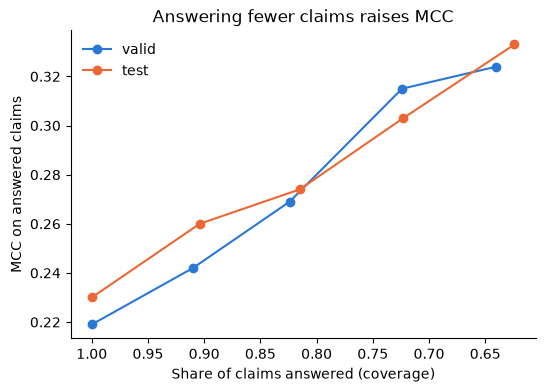


=== Bootstrap 95% intervals, test set ===
              2.5%  median  97.5%
M1 MCC       0.177   0.234  0.290
M6 MCC       0.179   0.230  0.280
M1 AUC       0.641   0.671  0.701
M1 log_loss  0.737   0.794  0.855
M6 - M1 MCC -0.049  -0.005  0.039

If the interval for 'M6 - M1 MCC' contains 0, the threshold did not change MCC beyond chance.


In [3]:
# ======================================================================================
# CELL 3: your part (A)  --  run AFTER cells 1 and 2
# M0 majority class | M1 plain Naive Bayes | M6 threshold (Romano) | M7 abstain band | bootstrap intervals
# Reads the files in 'shared' made by cell 2. Writes results_A.csv, abstain_table.csv, fig5_abstain.png.
# ======================================================================================
from scipy.special import expit
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, matthews_corrcoef,
                             roc_auc_score, log_loss, brier_score_loss)

rd = lambda f: pd.read_csv(os.path.join(SHARED_DIR, f))
prior = float(open(os.path.join(SHARED_DIR, "prior.txt")).read())
y_tr = rd("labels_train.csv")["y"].values
y_va = rd("labels_valid.csv")["y"].values
y_te = rd("labels_test.csv")["y"].values
feat = lambda df: df.drop(columns=["ID"])
S_tr = prior + feat(rd("train_oof_llr.csv")).sum(axis=1).values     # speaker-grouped out-of-fold scores
S_va = prior + feat(rd("valid_llr.csv")).sum(axis=1).values
S_te = prior + feat(rd("test_llr.csv")).sum(axis=1).values

def row(y, S, pred):
    p = np.clip(expit(S), 1e-6, 1 - 1e-6)
    return {"accuracy": accuracy_score(y, pred), "balanced_acc": balanced_accuracy_score(y, pred),
            "MCC": matthews_corrcoef(y, pred), "AUC": roc_auc_score(y, S),
            "Brier": brier_score_loss(y, p), "log_loss": log_loss(y, p)}

# ---- M6: threshold chosen on the grouped out-of-fold training scores (Romano idea)
tau = best_threshold(y_tr, S_tr, "mcc")
print("M6 threshold tau = %.3f   (M1 uses 0)" % tau)

rows = {}
for name, y, S in [("valid", y_va, S_va), ("test", y_te, S_te)]:
    rows[("M0 majority class (always False)", name)] = row(y, np.full(len(y), prior), np.zeros(len(y), int))
    rows[("M1 plain Naive Bayes (threshold 0)", name)] = row(y, S, (S > 0).astype(int))
    rows[("M6 + threshold (Romano)", name)] = row(y, S, (S > tau).astype(int))
res = pd.DataFrame(rows).T.round(3)
res.index.names = ["model", "split"]
pd.set_option("display.width", 200)
print("\n=== Results (valid and test) ===")
print(res)
res.to_csv(os.path.join(SHARED_DIR, "results_A.csv"))

# ---- M7: abstain band. Claims with |S - tau| <= delta get 'uncertain'. delta is set on the training scores
#          so that a target share of claims (coverage) is answered.
def abstain_rows(y, S, split):
    out = []
    for cov in [1.0, 0.9, 0.8, 0.7, 0.6]:
        delta = np.quantile(np.abs(S_tr - tau), 1 - cov) if cov < 1 else -1.0
        ans = np.abs(S - tau) > delta
        pred = (S[ans] > tau).astype(int)
        out.append({"split": split, "target_coverage": cov, "actual_coverage": ans.mean(),
                    "answered_claims": int(ans.sum()), "accuracy_on_answered": accuracy_score(y[ans], pred),
                    "MCC_on_answered": matthews_corrcoef(y[ans], pred),
                    "share_True_among_answered": y[ans].mean()})
    return out
ab = pd.DataFrame(abstain_rows(y_va, S_va, "valid") + abstain_rows(y_te, S_te, "test")).round(3)
print("\n=== M7 abstain band (answer only the claims the model is surest about) ===")
print(ab.to_string(index=False))
ab.to_csv(os.path.join(SHARED_DIR, "abstain_table.csv"), index=False)

import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(6, 4))
for split, col in [("valid", "#2a78d6"), ("test", "#eb6834")]:
    d = ab[ab["split"] == split]
    ax.plot(d["actual_coverage"], d["MCC_on_answered"], marker="o", color=col, label=split)
ax.set_xlabel("Share of claims answered (coverage)"); ax.set_ylabel("MCC on answered claims")
ax.set_title("Answering fewer claims raises MCC"); ax.invert_xaxis(); ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
os.makedirs(OUT_DIR, exist_ok=True)
fig.savefig(os.path.join(OUT_DIR, "fig5_abstain.png"), dpi=160, bbox_inches="tight")
plt.show()

# ---- bootstrap 95% intervals on the test set (1000 resamples of the test claims)
rng = np.random.RandomState(0)
n = len(y_te)
boot = {"M1 MCC": [], "M6 MCC": [], "M1 AUC": [], "M1 log_loss": [], "M6 - M1 MCC": []}
p1, p6 = (S_te > 0).astype(int), (S_te > tau).astype(int)
for _ in range(1000):
    i = rng.randint(0, n, n)
    if y_te[i].min() == y_te[i].max():
        continue
    m1, m6 = matthews_corrcoef(y_te[i], p1[i]), matthews_corrcoef(y_te[i], p6[i])
    boot["M1 MCC"].append(m1); boot["M6 MCC"].append(m6); boot["M6 - M1 MCC"].append(m6 - m1)
    boot["M1 AUC"].append(roc_auc_score(y_te[i], S_te[i]))
    boot["M1 log_loss"].append(log_loss(y_te[i], np.clip(expit(S_te[i]), 1e-6, 1 - 1e-6)))
ci = pd.DataFrame({k: {"2.5%": np.percentile(v, 2.5), "median": np.median(v), "97.5%": np.percentile(v, 97.5)}
                   for k, v in boot.items()}).T.round(3)
print("\n=== Bootstrap 95% intervals, test set ===")
print(ci)
ci.to_csv(os.path.join(SHARED_DIR, "bootstrap_ci_test.csv"))
print("\nIf the interval for 'M6 - M1 MCC' contains 0, the threshold did not change MCC beyond chance.")
